## EDA(Exploratory Data Analysis)

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


                mean           std           min          max
age        43.460000     15.226544     18.000000     69.00000
income  58415.939261  15561.815034  13286.861094  91243.95332
score       0.518197      0.288367      0.023755      0.99705


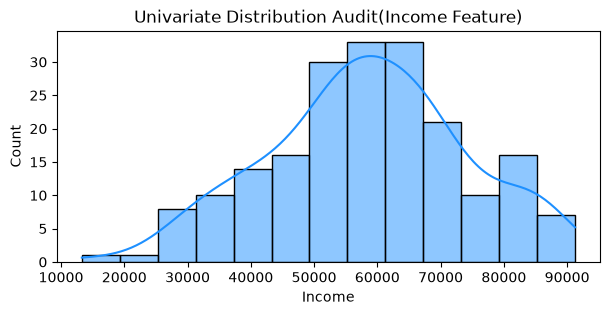

In [7]:
df_eda = pd.DataFrame({
    'age':np.random.randint(18,70,200),
    'income':np.random.normal(60000,15000,200),
    'score':np.random.rand(200)
})

profile_summary = df_eda.describe().T[["mean","std","min","max"]]
print(profile_summary)

plt.figure(figsize=(7,3))
sns.histplot(df_eda['income'],kde=True, color='dodgerblue')
plt.title('Univariate Distribution Audit(Income Feature)')
plt.xlabel('Income')
plt.show()

In [9]:
df_audit = pd.DataFrame({
    'id':[1,2,3,4,5],
    'status':['Active','Pending','Pending','Closed',None],
    'amount':[100,200,200,-50,500]
})

null_counts = df_audit.isnull().sum()
duplicate_count = df_audit.duplicated().sum()
print("Null Counts Per Column:\n",null_counts)
print("Duplicate Rows Count:\n",duplicate_count)

Null Counts Per Column:
 id        0
status    1
amount    0
dtype: int64
Duplicate Rows Count:
 0


## Data Schema Validate with Pandas Schema

In [16]:
def validate_schema(df):
    errors = []
    if not pd.api.types.is_integer_dtype(df['age']):
        errors.append('Age must be integer')
    if (df['age'] < 0).any():
        errors.append('Age can not be negative')

df_test = pd.DataFrame({'age':[25,30,-5,45]})

validation_error = validate_schema(df_test)
print("Schema Validation Errors Found:",validation_error)

# def validate_schema(df):
#     errors = []
#     if not pd.api.types.is_integer_dtype(df['age']):
#         errors.append('Age must be integer')
#     if (df['age'] < 0).any():
#         errors.append('Age cannot be negative')
#     return errors


# df_test = pd.DataFrame({'age': [25, 30, -5, 45]})

# validation_errors = validate_schema(df_test)
# print('Schema Validation Errors Found:', validation_errors)

Schema Validation Errors Found: None


Distribution Summary Statistics:
 department            HR             IT
count         100.000000     100.000000
mean        55178.436696   83961.534826
std          7629.351729    9081.684280
min         39649.830278   58802.548959
25%         48554.715815   78990.943295
50%         55672.857360   83730.437082
75%         59305.363581   89059.520520
max         76761.353333  103522.781845


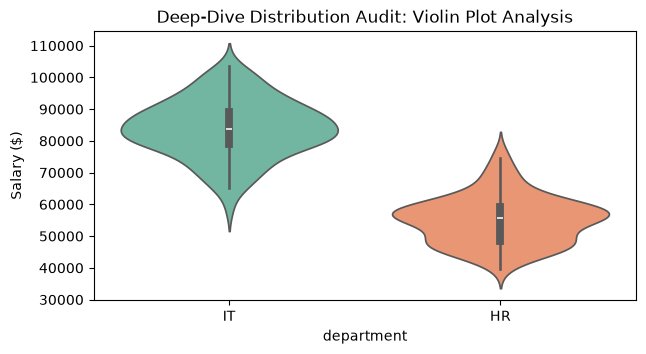

In [17]:
np.random.seed(seed=42)
df_dist = pd.DataFrame({
    'department':['IT']*100 + ['HR'] * 100,
    'salary': np.concatenate([np.random.normal(85000,10000,100),np.random.normal(55000,8000,100)])

})

print("Distribution Summary Statistics:\n",df_dist.groupby('department')['salary'].describe().T)
# Visualization
plt.figure(figsize=(7,3.5))
sns.violinplot(x='department',y='salary',hue='department',data = df_dist, palette='Set2', legend=False)
plt.title("Deep-Dive Distribution Audit: Violin Plot Analysis")
plt.ylabel('Salary ($)')
plt.show()

Correlation Matrix:
            feature_a  feature_b
feature_a   1.000000  -0.136422
feature_b  -0.136422   1.000000


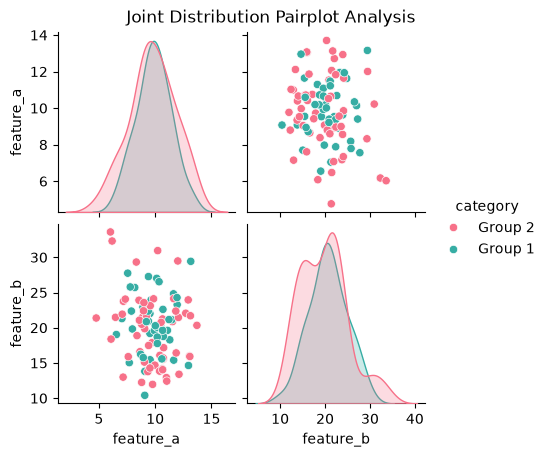

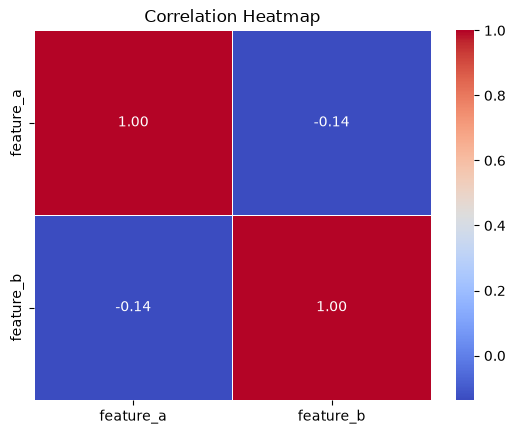

In [21]:
np.random.seed(42)
df_joint = pd.DataFrame({
	'feature_a': np.random.normal(10, 2, 100),
    'feature_b': np.random.normal(20, 5, 100),
    'category': np.random.choice(['Group 1', 'Group 2'], 100)
})

# Correlation matrix check
print("Correlation Matrix:\n", df_joint[['feature_a', 'feature_b']].corr())

# Visualization
sns.pairplot(df_joint, hue='category', height=2.2, palette='husl')
plt.suptitle('Joint Distribution Pairplot Analysis', y=1.02)
plt.show()

sns.heatmap(
    df_joint[['feature_a', 'feature_b']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [22]:
df_breakdown = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South', 'East', 'East'],
    'sales': [250, 300, 450, 400, 150, 180]
})

segment_summary = df_breakdown.groupby('region')['sales'].agg(['mean', 'median', 'std']).reset_index()
print(
    "Segment Breakdown Summary:\n",
    segment_summary.to_string(index=False),
)

Segment Breakdown Summary:
 region  mean  median       std
  East 165.0   165.0 21.213203
 North 275.0   275.0 35.355339
 South 425.0   425.0 35.355339


## Skewness and 

In [23]:
from scipy.stats import skew

Original Skewness: 1.4409012249947706
Log-Transformed Skewness: 0.33730012283200667


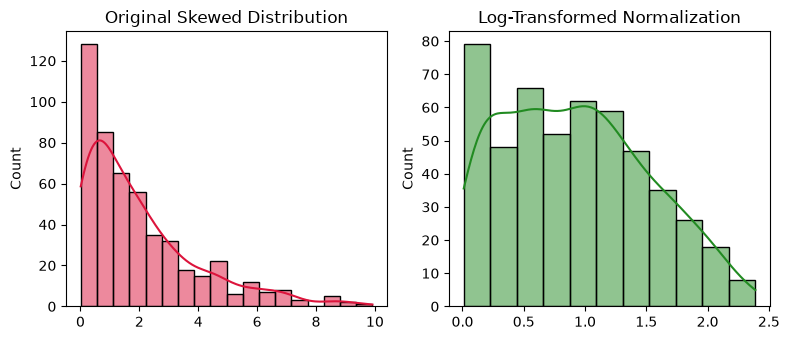

In [24]:
np.random.seed(42) 
skewed_data = np.random.exponential(scale=2.0, size=500) 
log_transformed = np.log1p(skewed_data) 

print("Original Skewness:", skew(skewed_data)) 
print("Log-Transformed Skewness:", skew(log_transformed)) 

# Visualization 
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5)) 
sns.histplot(skewed_data, kde=True, ax=axes[0], color='crimson') 
axes[0].set_title('Original Skewed Distribution') 
sns.histplot(log_transformed, kde=True, ax=axes[1], color='forestgreen') 
axes[1].set_title('Log-Transformed Normalization') 
plt.tight_layout() 
plt.show()

In [ ]:
import numpy as np
from scipy import stats

mixed_data = np.array([-5.0,-1.0,0.0,3.0,50.0])

transformed_yeojohnson, fitted_lambda_yj = stats.yeojohnson(mixed_data)

print("Original Data(with negativea):", mixed_data)
print("Teo-Johnson Transformed: ",np.round(transformed_yeojohnson,2))
print(f"Optimal Lambda found by ye")